# Classification and Regression Tree

$\underline{Problem Statement}$: Predicting India's Match Outcomes with a CART Model

In [129]:
# Importing the necessary Modules
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree # to split data into training and testing sets
from sklearn.model_selection import cross_val_score # for cross validation
from sklearn.metrics import confusion_matrix # to create a confusion matrix

In [130]:
import os
os.getcwd()

'C:\\Users\\TeNeT'

In [131]:
df = pd.read_csv('Sports Data_547601343_1788497867256.csv')
df.head()

,Game_number,Result,Avg_team_Age,Match_light_type,Match_format,Bowlers_in_team,Wicket_keeper_in_team,All_rounder_in_team,First_selection,Opponent,...,Max_run_scored_1over,Max_wicket_taken_1over,Extra_bowls_bowled,Min_run_given_1over,Min_run_scored_1over,Max_run_given_1over,extra_bowls_opponent,player_highest_run,Players_scored_zero,player_highest_wicket
0,Game_1,1,18,Day,ODI,3,1,3,Bowling,Srilanka,...,13,3,0,2,3,6,0,54,3,1
1,Game_2,0,24,Day,T20,3,1,4,Batting,Zimbabwe,...,12,1,0,0,3,6,0,69,2,1
2,Game_3,1,24,Day and Night,T20,3,1,2,Bowling,Zimbabwe,...,14,4,0,0,3,6,0,69,3,1
3,Game_4,0,24,Day,ODI,2,1,2,Bowling,Kenya,...,15,4,0,2,3,6,0,73,3,1
4,Game_5,1,24,Night,ODI,1,1,3,Bowling,Srilanka,...,12,4,0,0,3,6,0,80,3,1


Let us now check for the missing values.

In [132]:
df.isnull().sum()

Game_number               0
Result                    0
Avg_team_Age              0
Match_light_type          0
Match_format              0
Bowlers_in_team           0
Wicket_keeper_in_team     0
All_rounder_in_team       0
First_selection           0
Opponent                  0
Season                    0
Audience_number           0
Offshore                  0
Max_run_scored_1over      0
Max_wicket_taken_1over    0
Extra_bowls_bowled        0
Min_run_given_1over       0
Min_run_scored_1over      0
Max_run_given_1over       0
extra_bowls_opponent      0
player_highest_run        0
Players_scored_zero       0
player_highest_wicket     0
dtype: int64

There are no missing values in the dataset and we can go ahead with building the model.

Let us check the number of rows and the number of columns in the dataframe.

In [133]:
print('The number of rows (observations) is:',df.shape[0],'\n''The number of columns(variables) is:',df.shape[1])

The number of rows (observations) is: 2930 
The number of columns(variables) is: 23


We will drop the ''Game_number', 'Wicket_keeper_in_team'' variable.

In [134]:
df=df.drop(['Game_number', 'Wicket_keeper_in_team'], axis=1)
df.head()

,Result,Avg_team_Age,Match_light_type,Match_format,Bowlers_in_team,All_rounder_in_team,First_selection,Opponent,Season,Audience_number,...,Max_run_scored_1over,Max_wicket_taken_1over,Extra_bowls_bowled,Min_run_given_1over,Min_run_scored_1over,Max_run_given_1over,extra_bowls_opponent,player_highest_run,Players_scored_zero,player_highest_wicket
0,1,18,Day,ODI,3,3,Bowling,Srilanka,Summer,9940,...,13,3,0,2,3,6,0,54,3,1
1,0,24,Day,T20,3,4,Batting,Zimbabwe,Summer,8400,...,12,1,0,0,3,6,0,69,2,1
2,1,24,Day and Night,T20,3,2,Bowling,Zimbabwe,Summer,13146,...,14,4,0,0,3,6,0,69,3,1
3,0,24,Day,ODI,2,2,Bowling,Kenya,Summer,7357,...,15,4,0,2,3,6,0,73,3,1
4,1,24,Night,ODI,1,3,Bowling,Srilanka,Summer,13328,...,12,4,0,0,3,6,0,80,3,1


Let us check the data types of each of the variables in the data.

In [135]:
df.dtypes

Result                    int64
Avg_team_Age              int64
Match_light_type            str
Match_format                str
Bowlers_in_team           int64
All_rounder_in_team       int64
First_selection             str
Opponent                    str
Season                      str
Audience_number           int64
Offshore                    str
Max_run_scored_1over      int64
Max_wicket_taken_1over    int64
Extra_bowls_bowled        int64
Min_run_given_1over       int64
Min_run_scored_1over      int64
Max_run_given_1over       int64
extra_bowls_opponent      int64
player_highest_run        int64
Players_scored_zero       int64
player_highest_wicket     int64
dtype: object

In [136]:
#We are prepping the data by segregating them into Target and independent variables to runt his model going forward

# Let us define the X(predictor) and Y(target) variables

X = df.drop("Result" , axis=1)

Y = df.pop("Result")
#we have made a copy of the data frame as the 'pop' function removes that particular variable from the data frame and stores 
# in another variable

In [137]:
# This line of code is to perform one hot encoding for Categorical Features
X = pd.get_dummies( X, drop_first = False )

In [138]:
list(X.columns)

['Avg_team_Age',
 'Bowlers_in_team',
 'All_rounder_in_team',
 'Audience_number',
 'Max_run_scored_1over',
 'Max_wicket_taken_1over',
 'Extra_bowls_bowled',
 'Min_run_given_1over',
 'Min_run_scored_1over',
 'Max_run_given_1over',
 'extra_bowls_opponent',
 'player_highest_run',
 'Players_scored_zero',
 'player_highest_wicket',
 'Match_light_type_Day',
 'Match_light_type_Day and Night',
 'Match_light_type_Night',
 'Match_format_20-20',
 'Match_format_ODI',
 'Match_format_T20',
 'Match_format_Test',
 'First_selection_Batting',
 'First_selection_Bowling',
 'Opponent_Australia',
 'Opponent_Bangladesh',
 'Opponent_England',
 'Opponent_Kenya',
 'Opponent_Pakistan',
 'Opponent_South Africa',
 'Opponent_Srilanka',
 'Opponent_West Indies',
 'Opponent_Zimbabwe',
 'Season_Rainy',
 'Season_Summer',
 'Season_Winter',
 'Offshore_No',
 'Offshore_Yes']

In [139]:
X.dtypes

Avg_team_Age                      int64
Bowlers_in_team                   int64
All_rounder_in_team               int64
Audience_number                   int64
Max_run_scored_1over              int64
Max_wicket_taken_1over            int64
Extra_bowls_bowled                int64
Min_run_given_1over               int64
Min_run_scored_1over              int64
Max_run_given_1over               int64
extra_bowls_opponent              int64
player_highest_run                int64
Players_scored_zero               int64
player_highest_wicket             int64
Match_light_type_Day               bool
Match_light_type_Day and Night     bool
Match_light_type_Night             bool
Match_format_20-20                 bool
Match_format_ODI                   bool
Match_format_T20                   bool
Match_format_Test                  bool
First_selection_Batting            bool
First_selection_Bowling            bool
Opponent_Australia                 bool
Opponent_Bangladesh                bool


We see that the data types of all the variables have been changed to either of $\underline{int64}$ or $\underline{float64}$.

In [140]:
#You shall notice One hot encoding converts catagorical variable (Levels) into seperate columns with binary values 
X.head()

,Avg_team_Age,Bowlers_in_team,All_rounder_in_team,Audience_number,Max_run_scored_1over,Max_wicket_taken_1over,Extra_bowls_bowled,Min_run_given_1over,Min_run_scored_1over,Max_run_given_1over,...,Opponent_Pakistan,Opponent_South Africa,Opponent_Srilanka,Opponent_West Indies,Opponent_Zimbabwe,Season_Rainy,Season_Summer,Season_Winter,Offshore_No,Offshore_Yes
0,18,3,3,9940,13,3,0,2,3,6,...,False,False,True,False,False,False,True,False,True,False
1,24,3,4,8400,12,1,0,0,3,6,...,False,False,False,False,True,False,True,False,True,False
2,24,3,2,13146,14,4,0,0,3,6,...,False,False,False,False,True,False,True,False,False,True
3,24,2,2,7357,15,4,0,2,3,6,...,False,False,False,False,False,False,True,False,True,False
4,24,1,3,13328,12,4,0,0,3,6,...,False,False,True,False,False,False,True,False,True,False


## Split the data into Train and Test.

Before building the model we should split the data into Train and Test. We will thus build a model on the training data and use this model to predict on the test data.

We will be doing a 70:30 split.
70% of the whole data will be used to train the data and then 30% of the data will be used for testing the model thus built.

Before splitting the data, we shall make a copy of the data frame.

In [141]:
data = df.copy()
data.head()
#Just keepipng the copy of the original dataset.

,Avg_team_Age,Match_light_type,Match_format,Bowlers_in_team,All_rounder_in_team,First_selection,Opponent,Season,Audience_number,Offshore,Max_run_scored_1over,Max_wicket_taken_1over,Extra_bowls_bowled,Min_run_given_1over,Min_run_scored_1over,Max_run_given_1over,extra_bowls_opponent,player_highest_run,Players_scored_zero,player_highest_wicket
0,18,Day,ODI,3,3,Bowling,Srilanka,Summer,9940,No,13,3,0,2,3,6,0,54,3,1
1,24,Day,T20,3,4,Batting,Zimbabwe,Summer,8400,No,12,1,0,0,3,6,0,69,2,1
2,24,Day and Night,T20,3,2,Bowling,Zimbabwe,Summer,13146,Yes,14,4,0,0,3,6,0,69,3,1
3,24,Day,ODI,2,2,Bowling,Kenya,Summer,7357,No,15,4,0,2,3,6,0,73,3,1
4,24,Night,ODI,1,3,Bowling,Srilanka,Summer,13328,No,12,4,0,0,3,6,0,80,3,1


In [142]:
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=.30, random_state=1)

Now that we have split the data into Train and Test, let us go ahead and build our Decision Tree Model.

## Building the Decision Tree

We will start by building a very basic Decision Tree model.

In [143]:
from sklearn import tree

In [144]:
dt_model = tree.DecisionTreeClassifier(criterion = 'gini',random_state=1,min_samples_split=2,
    min_samples_leaf=1)

In the above code snippet we have defined a Decision Tree (which is to be used for classification problems) with the splitting criteria for each node as 'gini'. The 'random_state' parameter ensures that each time we run the code snippet the values remains the same. 

In the above code snippet default values of 'min_samples_split' and 'min_samples_leaf' is taken as 2 and 1 respectively.

Now, that we have defined a Decision Tree, let us go ahead and build the model on the training data.

In [145]:
dt_model.fit(X_train, Y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",1
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples a

## Visualizing the Decision Tree

Now, that we have built the tree let us go ahead and visualize the tree to understand the various nuances of the Classification Tree that we just built.

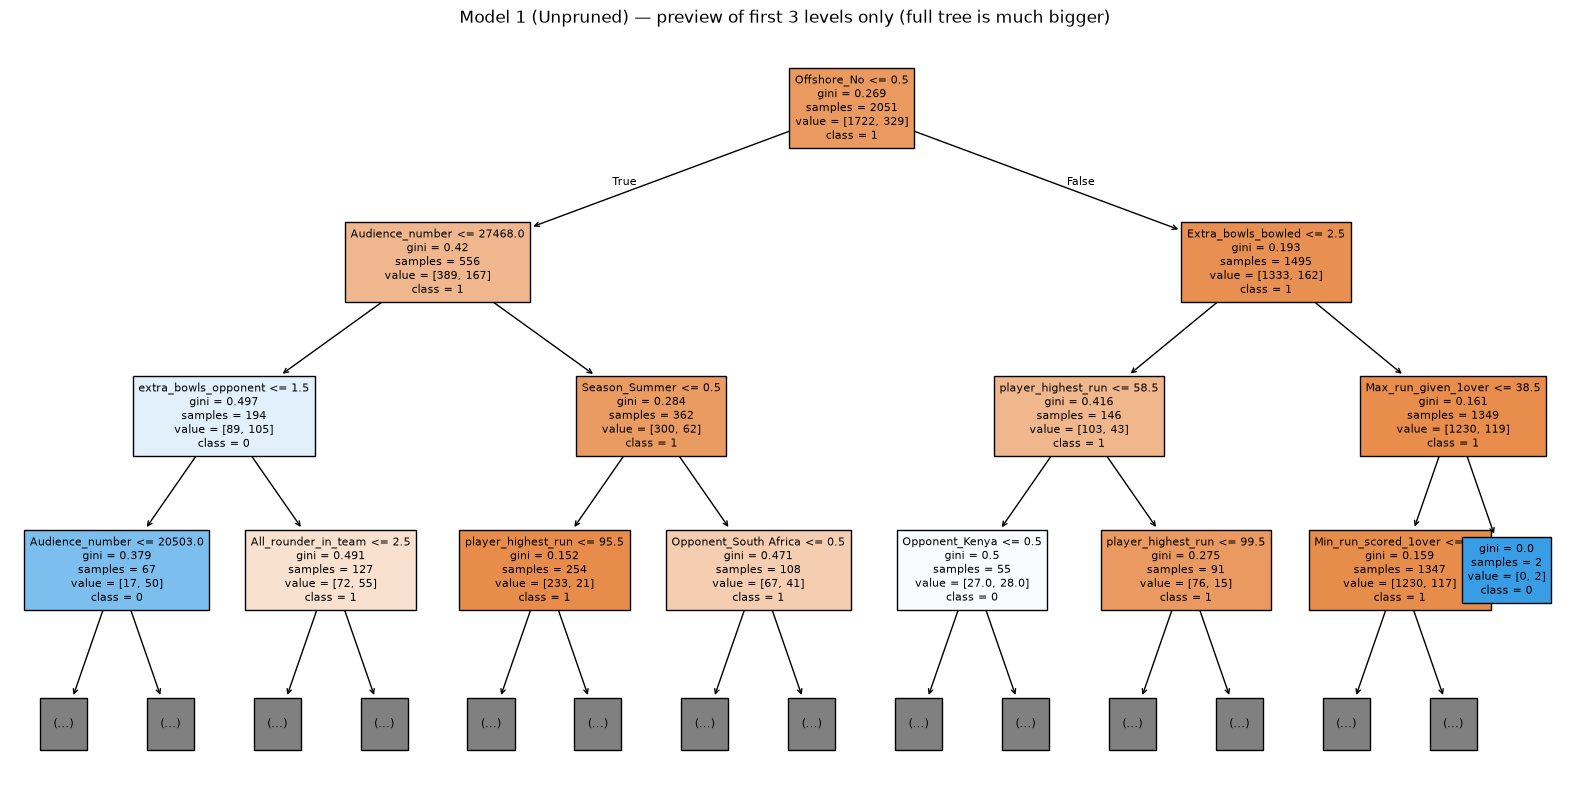

In [146]:
plt.figure(figsize=(20,10))
plot_tree(dt_model, feature_names=X_train.columns, class_names=[str(c) for c in Y.unique()],
          filled=True, max_depth=3, fontsize=8)
plt.title("Model 1 (Unpruned) — preview of first 3 levels only (full tree is much bigger)")
plt.show()


In [147]:
pd.Series(dt_model.feature_importances_,index=X_train.columns).sort_values(ascending=False)

Audience_number                   0.191377
player_highest_run                0.125105
Extra_bowls_bowled                0.070732
Max_run_scored_1over              0.055920
Players_scored_zero               0.055458
Offshore_No                       0.054086
All_rounder_in_team               0.053254
Season_Summer                     0.046588
extra_bowls_opponent              0.044358
Min_run_scored_1over              0.043347
Bowlers_in_team                   0.041813
Opponent_South Africa             0.037016
Max_run_given_1over               0.026117
Max_wicket_taken_1over            0.023845
Opponent_Kenya                    0.019162
player_highest_wicket             0.015306
Min_run_given_1over               0.010920
Match_light_type_Night            0.010672
Match_light_type_Day and Night    0.009251
Opponent_Srilanka                 0.009232
Opponent_Pakistan                 0.008228
Season_Winter                     0.008016
Opponent_Australia                0.007570
Match_forma

From the above output, we can see that 'Audience_number' is the most important variable followed by 'player_highest_run' and so on.

Let us take a look at the overall accuracy of the train and test data using the model that we just built.

In [148]:
#Train Data
dt_model.score(X_train,Y_train)

1.0

In [149]:
#Test Data
dt_model.score(X_test,Y_test)

0.9328782707622298

The accuracy on the Training Data is 100% and the accuracy on the Test Data is lesser substantially. The model has surely been overfitted. 
Thus, we need to prune or regularize the tree.

## Pruning/Regularizing the Tree

For Pruning/Regularizing the Tree we need to be sure as to what parameters and how to prune the tree.

# Method 1 for Pruning:

#### (by visualizing the tree)

In [150]:
reg_dt_model = tree.DecisionTreeClassifier(criterion = 'gini', 
                                       max_depth=2,#upto this depth is where the tree has grown uniformly
                                      min_samples_leaf=20, #ensures that every terminal node (leaf node) have at least 10
                                      #observations in it
                                      min_samples_split=6) #for every node to be split into two child nodes that particular
                                      #node should have at least 30 observations  
    
#Genral Thumb rule: 1% to 3% of the data should be the 'min_samples_split' and one third times the 'min_samples_split'
#should be 'min_samples_leaf.These are only a rough guideline value.
#Here, we have chose 1% of our training data which has 14,000 observations (140 observations for min_samples_split)

In [151]:
reg_dt_model.fit(X_train, Y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",2
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",6
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",20
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples 

Now that we have built the Pruned/Regularized Classification Tree let us visualize the tree to understand the nuances of the tree.

### Method 1:

In [152]:
# Define the path of the dot.file from the output of this code below
os.getcwd()

'C:\\Users\\TeNeT'

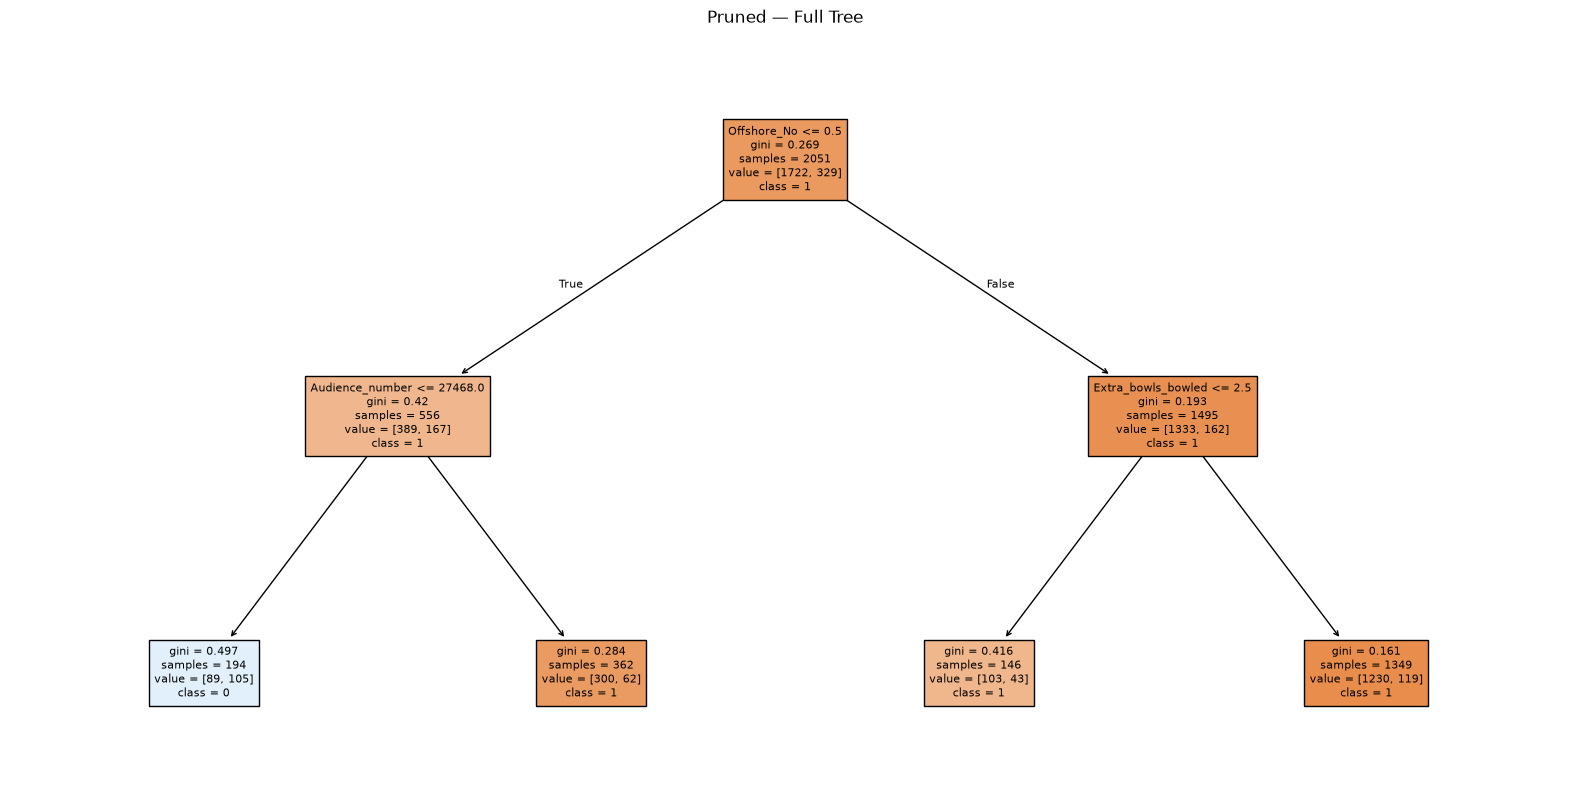

In [153]:
plt.figure(figsize=(20,10))
plot_tree(reg_dt_model, feature_names=X_train.columns, class_names=[str(c) for c in Y.unique()],
          filled=True, fontsize=8)
plt.title("Pruned — Full Tree")
plt.show()

Let us now go ahead and predict both the classes and the probability values on the test data using the Pruned/Regularized Decision Tree.

In [154]:
#We are only predicting the classes over here. Python by default takes the 0.5 cutoff of the probability values while
#predicting the classes

Y_train_predict_class = reg_dt_model.predict(X_train)
Y_test_predict_class = reg_dt_model.predict(X_test)

In [155]:
#Here, we are predicting the probabilities and we can manually input a cutoff value which is different than 0.5.

Y_train_predict_prob = reg_dt_model.predict_proba(X_train)
Y_test_predict_prob = reg_dt_model.predict_proba(X_test)

# Evaluation of the Train and Test Models.

Let us first build the confusion matrix, followed by the Classification Report and then the ROC (Receiver Operator Charateristic Curve) curve and the AUC (Area Under the Curve) value.

In [156]:
from sklearn import metrics

First we will evaluate the model on the Training Data.

In [157]:
print(metrics.confusion_matrix(Y_train,Y_train_predict_class))

[[1633   89]
 [ 224  105]]


In [158]:
tn, fp, fn, tp = metrics.confusion_matrix(Y_train,Y_train_predict_class).ravel()
print('True Negative:',tn,'\n''False Positives:' ,fp,'\n''False Negatives:', fn,'\n''True Positives:', tp)

True Negative: 1633 
False Positives: 89 
False Negatives: 224 
True Positives: 105


Let us now go ahead and print the classification report to check the various other parameters.

In [159]:
print(metrics.classification_report(Y_train,Y_train_predict_class))

              precision    recall  f1-score   support

           0       0.88      0.95      0.91      1722
           1       0.54      0.32      0.40       329

    accuracy                           0.85      2051
   macro avg       0.71      0.63      0.66      2051
weighted avg       0.83      0.85      0.83      2051



We have been able to predict 85% of the target variables correctly.

Let us check the confusion matrix for the test data.

In [160]:
print(metrics.confusion_matrix(Y_test,Y_test_predict_class),'\n')
tn, fp, fn, tp = metrics.confusion_matrix(Y_test,Y_test_predict_class).ravel()
print('True Negative:',tn,'\n''False Positives:' ,fp,'\n''False Negatives:', fn,'\n''True Positives:', tp)

[[696  39]
 [101  43]] 

True Negative: 696 
False Positives: 39 
False Negatives: 101 
True Positives: 43


Let us now go ahead and print the classification report for the test data and compare between train and test.

In [161]:
print(metrics.classification_report(Y_test,Y_test_predict_class))

              precision    recall  f1-score   support

           0       0.87      0.95      0.91       735
           1       0.52      0.30      0.38       144

    accuracy                           0.84       879
   macro avg       0.70      0.62      0.64       879
weighted avg       0.82      0.84      0.82       879



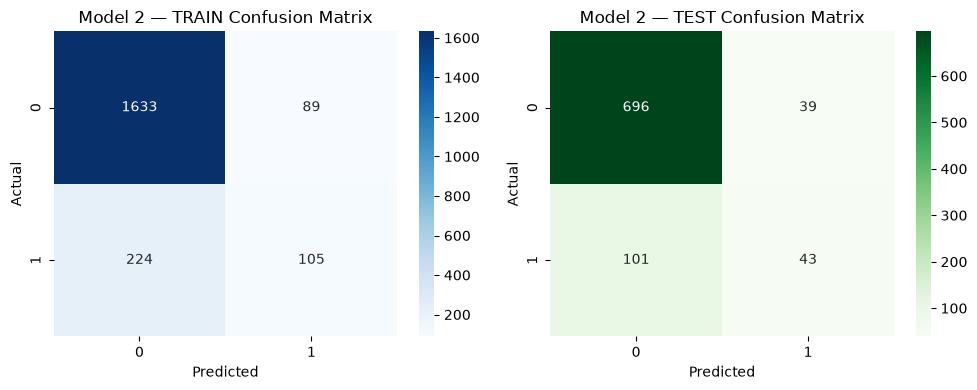

In [162]:
fig, axes = plt.subplots(1, 2, figsize=(10,4))
sns.heatmap(metrics.confusion_matrix(Y_train, Y_train_predict_class), annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('Model 2 — TRAIN Confusion Matrix'); axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('Actual')

sns.heatmap(metrics.confusion_matrix(Y_test, Y_test_predict_class), annot=True, fmt='d', cmap='Greens', ax=axes[1])
axes[1].set_title('Model 2 — TEST Confusion Matrix'); axes[1].set_xlabel('Predicted'); axes[1].set_ylabel('Actual')
plt.tight_layout()
plt.show()


# END